# 02. Kiểm tra chất lượng dữ liệu

Notebook này rà soát bản ghi trùng, dữ liệu thiếu, giá trị đặc biệt, ngoại lai và quan hệ chưa nhất quán trước khi tạo đặc trưng. Các phân tích theo hồ sơ dùng đúng **184.506 ID train** từ notebook 01; kết quả khóa và liên kết toàn nguồn được kế thừa từ bước trước.

Giá trị cực đoan hoặc khác kỳ vọng chưa đủ để kết luận dữ liệu sai. Mục tiêu là ghi lại bằng chứng và giới hạn diễn giải để bước chuẩn bị dữ liệu có căn cứ.


## Mục lục

- [01. Đọc dữ liệu và xác nhận phạm vi train](#part-1)
- [02. Kiểm tra giá trị trùng lặp](#part-2)
- [03. Kiểm tra dữ liệu thiếu](#part-3)
- [04. Kiểm tra phạm vi và giá trị đặc biệt](#part-4)
- [05. Kiểm tra logic và tính nhất quán](#part-5)
- [06. Xuất dữ liệu cho EDA](#part-6)
- [07. Tổng kết và đề xuất xử lý](#part-7)

<a id="muc-01"></a>

<a id="part-1"></a>

## 01. Đọc dữ liệu và xác nhận phạm vi train

Mục này nạp đúng ID train từ notebook 01, rồi kiểm tra số hồ sơ, ID duy nhất và tỷ lệ TARGET. Không chia lại dữ liệu và không dùng nhãn validation/test trong các phân tích tiếp theo.

`HomeCreditQuality` kế thừa thao tác đọc dữ liệu từ `HomeCreditData`. Notebook chạy độc lập trên kernel mới, nạp dữ liệu một lần và tái sử dụng kết quả.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_rows', 25)
plt.rcParams['figure.figsize'] = (9, 4)

ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from connectors.Connector import Connector
from models.HomeCreditQuality import HomeCreditQuality

In [2]:
connector = Connector()
connector.connect()


quality = HomeCreditQuality(connector)
train = quality.loadTrain()
split = quality.split
train_ids = split.loc[split['split'] == 'train', 'SK_ID_CURR']

In [3]:
target_counts = train['TARGET'].value_counts().sort_index()
target_summary = target_counts.rename_axis('TARGET').to_frame('n')
target_summary['pct'] = target_summary['n'] / len(train) * 100
display(target_summary)
print('Số hồ sơ train:', len(train))

,n,pct
TARGET,,
0,169611,91.927092
1,14895,8.072908


Số hồ sơ train: 184506


### Kết luận mục 01

Train có **184.506 hồ sơ**, trong đó **14.895 hồ sơ TARGET = 1 (8,073%)**. Hai lớp mất cân bằng, nên accuracy không đủ để đánh giá mô hình. EDA tiếp tục dùng đúng các ID này, không tạo lại split.


<a id="muc-02"></a>

<a id="part-2"></a>

## 02. Kiểm tra giá trị trùng lặp

<a id="muc-02-1"></a>

### 02.1. Bản ghi trùng hoàn toàn
đếm số dòng trùng dư khi so sánh toàn bộ cột của từng bảng, kể cả trường hợp nằm ở hai lô khác nhau; xem ví dụ nếu có. Đây là kiểm tra kỹ thuật toàn nguồn.

Truy vấn MySQL theo lô để hạn chế RAM; không đưa cột kỹ thuật `_source_row` vào so trùng. Hash chỉ giúp tìm ứng viên; nếu hash lặp thì đọc lại các ứng viên và so sánh chính xác toàn bộ cột bằng `duplicated()`. Số dòng trùng dư không phải số nhóm trùng.

**Đếm dòng trùng hoàn toàn**

In [4]:
duplicate_summary = quality.processDuplicates()
display(duplicate_summary)


application_test : đã kiểm tra trùng toàn bộ 48744 dòng
application_train : đã kiểm tra trùng toàn bộ 307511 dòng
bureau : đã kiểm tra trùng toàn bộ 1716428 dòng
bureau_balance : đã kiểm tra trùng toàn bộ 27299925 dòng
credit_card_balance : đã kiểm tra trùng toàn bộ 3840312 dòng
installments_payments : đã kiểm tra trùng toàn bộ 13605401 dòng
pos_cash_balance : đã kiểm tra trùng toàn bộ 10001358 dòng
previous_application : đã kiểm tra trùng toàn bộ 1670214 dòng


,table,rows,duplicate_excess_rows
0,application_test,48744,0
1,application_train,307511,0
2,bureau,1716428,0
3,bureau_balance,27299925,0
4,credit_card_balance,3840312,0
5,installments_payments,13605401,0
6,pos_cash_balance,10001358,0
7,previous_application,1670214,0


**Xem ví dụ nếu phát hiện trùng**

In [5]:
for table_name, examples in quality.duplicate_examples.items():
    print('Ví dụ dòng trùng:', table_name)
    display(examples)


Cả **8 bảng đều có 0 dòng trùng hoàn toàn**. Không có bản ghi nào cần loại vì trùng toàn bộ cột. Các dòng lịch sử lặp theo một khóa nghiệp vụ được kiểm tra riêng ở mục 02.2.


<a id="muc-02-2"></a>

### 02.2. Lặp khóa theo đơn vị quan sát
đối chiếu khóa hồ sơ, khoản vay và snapshot tháng đã kiểm tra ở notebook 01; đếm riêng số dòng lặp dư của khóa kỳ trả nợ trên train. Không đánh đồng lặp khóa kỳ với trùng toàn bộ bản ghi.
`processHistory()` đọc từng nguồn một lần và trả về `history_results`: các bảng missing, coverage, tiền, thời gian, logic và ví dụ đối soát. Các mục sau lấy rõ từng bảng từ dict này; không sửa trực tiếp các bảng dùng chung. Mỗi nguồn được lọc đúng train; bureau_balance nối qua bureau để xác định chủ hồ sơ. Chỉ tải các cột cần kiểm tra; thống kê thiếu toàn bộ cột được tổng hợp bằng SQL. Sau mỗi nguồn, giải phóng dữ liệu chi tiết và giữ bảng kết quả, ví dụ cùng tổng hợp cấp hồ sơ.

**Đọc kết quả khóa từ notebook 01**

In [6]:
key_checks = pd.read_csv(ROOT / 'reports/data_understanding/key_checks.csv')
display(key_checks)


,table,key,rows,missing_key_rows,duplicate_key_rows,expected_unique
0,application_train,SK_ID_CURR,307511,0,0,True
1,application_test,SK_ID_CURR,48744,0,0,True
2,bureau,SK_ID_BUREAU,1716428,0,0,True
3,bureau_balance,"SK_ID_BUREAU, MONTHS_BALANCE",27299925,0,0,True
4,previous_application,SK_ID_PREV,1670214,0,0,True
5,pos_cash_balance,"SK_ID_PREV, MONTHS_BALANCE",10001358,0,0,True
6,credit_card_balance,"SK_ID_PREV, MONTHS_BALANCE",3840312,0,0,True
7,installments_payments,"SK_ID_PREV, NUM_INSTALMENT_VERSION, NUM_INSTAL...",13605401,0,653483,False


**Tổng hợp lịch sử để dùng trong các phần tiếp theo**

In [7]:
# Mỗi nguồn được tổng hợp một lần; các phần sau dùng lại kết quả.
history_results = quality.processHistory()
history_missing = history_results['missing']
history_coverage = history_results['coverage']
installment_key = quality.installment_key
display(history_results['installment_key_summary'])


bureau : đã kiểm tra lịch sử train 879858 dòng
bureau_balance : đã kiểm tra lịch sử train 8872260 dòng
previous_application : đã kiểm tra lịch sử train 848478 dòng
pos_cash_balance : đã kiểm tra lịch sử train 5125192 dòng
credit_card_balance : đã kiểm tra lịch sử train 1941181 dòng
installments_payments : đã kiểm tra lịch sử train 6959239 dòng


,train_payment_rows,duplicate_key_excess_rows,rows_in_repeated_groups,repeated_key_groups
0,6959239,339914,673130,333216


**Xem các khóa kỳ có nhiều lần thanh toán**

In [8]:
display(history_results['sample_keys'])


,SK_ID_PREV,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER
10,1410565,1.0,1
13,1840786,1.0,11
23,1895324,1.0,6
25,1220449,1.0,16
26,2726751,1.0,20


### Kết luận mục 02

Các khóa dự kiến duy nhất từ notebook 01 không thiếu hoặc lặp. Trên train, khóa kỳ trả nợ `(SK_ID_PREV, NUM_INSTALMENT_VERSION, NUM_INSTALMENT_NUMBER)` có **339.914 dòng lặp dư thuộc 333.216 kỳ**; toàn nguồn có **653.483 dòng lặp dư**. Đây không phải trùng hoàn toàn: một kỳ có thể gồm nhiều lần thanh toán. Mục 05.2 kiểm tra cách tổng hợp các lần trả.


<a id="muc-03"></a>

<a id="part-3"></a>

## 03. Kiểm tra dữ liệu thiếu

<a id="muc-03-1"></a>

### 03.1. Thiếu trong hồ sơ hiện tại
tính số lượng và tỷ lệ thiếu của từng cột application trên train; xác định cột thiếu nhiều hoặc thiếu hoàn toàn và biểu diễn 15 cột thiếu nhiều nhất.

**Tính tỷ lệ thiếu trong hồ sơ**

In [9]:
application_missing = train.isna().sum().rename_axis('column').to_frame('missing_n')
application_missing['missing_pct'] = application_missing['missing_n'] / len(train) * 100
application_missing = application_missing.sort_values('missing_pct', ascending=False)
display(application_missing.head(20))
print('Số cột thiếu hoàn toàn:', (application_missing['missing_pct'] == 100).sum())


,missing_n,missing_pct
column,,
COMMONAREA_AVG,128797,69.806402
COMMONAREA_MODE,128797,69.806402
COMMONAREA_MEDI,128797,69.806402
NONLIVINGAPARTMENTS_MEDI,127968,69.357094
NONLIVINGAPARTMENTS_MODE,127968,69.357094
NONLIVINGAPARTMENTS_AVG,127968,69.357094
FONDKAPREMONT_MODE,126060,68.322981
LIVINGAPARTMENTS_AVG,125984,68.281790
LIVINGAPARTMENTS_MEDI,125984,68.281790


Số cột thiếu hoàn toàn: 0


**Vẽ các cột thiếu nhiều nhất**

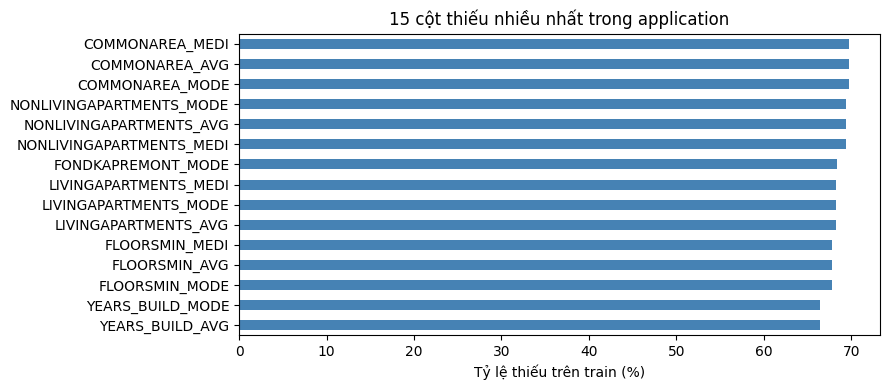

In [10]:
application_missing.head(15)['missing_pct'].sort_values().plot.barh(color='steelblue')
plt.xlabel('Tỷ lệ thiếu trên train (%)')
plt.ylabel('')
plt.title('15 cột thiếu nhiều nhất trong application')
plt.tight_layout()
plt.show()


Các nhóm `COMMONAREA_AVG/MEDI/MODE` thiếu khoảng **69,81%**; nhóm `NONLIVINGAPARTMENTS_AVG/MEDI` thiếu khoảng **69,36%**. Tỷ lệ cao là căn cứ để xem xét ý nghĩa và khả năng sử dụng của thông tin nhà ở, nhưng chưa đủ để tự động loại cột hoặc điền giá trị.


<a id="muc-03-2"></a>

### 03.2. Thiếu trong lịch sử và mức độ bao phủ
tính thiếu từng cột lịch sử thuộc train và tỷ lệ hồ sơ train có lịch sử ở mỗi nguồn. Tách ba trường hợp: ô thiếu giá trị, hồ sơ không có dòng lịch sử, bản ghi không nối được bảng cha.
Lần gọi `processHistory()` tại đây dùng kết quả đã giữ ở mục 02.2, không truy vấn lại các bảng lịch sử.

**Xem độ bao phủ lịch sử**

In [11]:
display(history_coverage)


,table,train_history_rows,train_with_history,train_without_history,coverage_pct
0,bureau,879858,158165,26341,85.723500
1,bureau_balance,8872260,55379,129127,30.014742
2,previous_application,848478,174636,9870,94.650580
3,pos_cash_balance,5125192,173672,10834,94.128104
4,credit_card_balance,1941181,52231,132275,28.308564
5,installments_payments,6959239,175000,9506,94.847864


**Xem các cột lịch sử thiếu nhiều nhất**

In [12]:
most_missing = history_missing.sort_values('missing_pct', ascending=False)
display(most_missing.head(15))


,column,missing_n,table,rows,missing_pct
34,RATE_INTEREST_PRIVILEGED,845561,previous_application,848478,99.656208
33,RATE_INTEREST_PRIMARY,845561,previous_application,848478,99.656208
16,AMT_ANNUITY,678271,bureau,879858,77.088689
8,AMT_CREDIT_MAX_OVERDUE,570398,bureau,879858,64.828415
26,AMT_DOWN_PAYMENT,449845,previous_application,848478,53.017874
32,RATE_DOWN_PAYMENT,449845,previous_application,848478,53.017874
40,NAME_TYPE_SUITE,417112,previous_application,848478,49.160025
52,DAYS_FIRST_DUE,336571,previous_application,848478,39.667617
51,DAYS_FIRST_DRAWING,336571,previous_application,848478,39.667617
54,DAYS_LAST_DUE,336571,previous_application,848478,39.667617


In [13]:
# Kết quả toàn vẹn liên kết toàn nguồn đã được tính trực tiếp ở notebook 01.
relationships = pd.read_csv(ROOT / 'reports/data_understanding/relationships.csv')
display(relationships[['table', 'missing_parent_rows', 'owner_conflict_rows',
                       'unresolved_owner_rows']])


,table,missing_parent_rows,owner_conflict_rows,unresolved_owner_rows
0,bureau,0,0,0
1,bureau_balance,3120184,0,3120184
2,previous_application,0,0,0
3,pos_cash_balance,340561,0,0
4,credit_card_balance,1082816,0,0
5,installments_payments,1250826,0,0


Trong train, installments có lịch sử cho **175.000/184.506 hồ sơ**, còn credit card có lịch sử cho **52.231/184.506 hồ sơ**. Hai cột `RATE_INTEREST_PRIMARY/PRIVILEGED` trong `previous_application` thiếu khoảng **99,66%**. Không có lịch sử không đồng nghĩa với lịch sử trả nợ tốt.

Kiểm tra toàn nguồn phát hiện **3.120.184 dòng `bureau_balance`** không nối được với `bureau`; các dòng này chưa xác định được hồ sơ hiện tại. Các nguồn lịch sử khác vẫn có `SK_ID_CURR` trực tiếp, nhưng độ bao phủ giữa các nguồn khác nhau.


<a id="muc-03-3"></a>

### 03.3. Thiếu theo điều kiện sở hữu xe
tính tỷ lệ thiếu OWN_CAR_AGE riêng trong nhóm có xe và không có xe; phân biệt thông tin có thể không áp dụng với trường hợp có xe nhưng chưa ghi nhận tuổi xe.

**Thiếu tuổi xe theo điều kiện sở hữu**

In [14]:
car_missing_view = train[['SK_ID_CURR', 'FLAG_OWN_CAR', 'OWN_CAR_AGE']].copy()
car_missing_view['age_missing'] = car_missing_view['OWN_CAR_AGE'].isna()
car_missing_summary = car_missing_view.groupby('FLAG_OWN_CAR', dropna=False).agg(
    n=('SK_ID_CURR', 'size'),
    age_missing_n=('age_missing', 'sum')
)
car_missing_summary['age_observed_n'] = car_missing_summary['n'] - car_missing_summary['age_missing_n']
car_missing_summary['age_missing_pct'] = car_missing_summary['age_missing_n'] / car_missing_summary['n'] * 100
display(car_missing_summary)


,n,age_missing_n,age_observed_n,age_missing_pct
FLAG_OWN_CAR,,,,
N,121925,121925,0,100.000000
Y,62581,4,62577,0.006392


**Xem hồ sơ có xe nhưng thiếu tuổi xe**

In [15]:
has_car = car_missing_view['FLAG_OWN_CAR'] == 'Y'
missing_car_age = car_missing_view['age_missing']
display(car_missing_view.loc[
    has_car & missing_car_age,
    ['SK_ID_CURR', 'FLAG_OWN_CAR', 'OWN_CAR_AGE']
])


,SK_ID_CURR,FLAG_OWN_CAR,OWN_CAR_AGE
18527,135867,Y,NaN
108663,310040,Y,NaN
137902,366246,Y,NaN
142058,374361,Y,NaN


Toàn bộ **121.925 hồ sơ không sở hữu xe** thiếu tuổi xe; trong **62.581 hồ sơ có xe**, chỉ **4 hồ sơ thiếu tuổi xe (0,0064%)**. Mẫu quan sát phù hợp với khả năng trường tuổi xe không áp dụng khi không có xe. Bốn trường hợp còn lại cần được phân biệt khi chuẩn bị dữ liệu; chưa điền giá trị hay kết luận cơ chế thiếu từ tỷ lệ này.


<a id="muc-03-4"></a>

### 03.4. Cơ chế thiếu: MCAR, MAR và MNAR
đối chiếu ba cơ chế thiếu với dữ liệu train; xem cờ thiếu của AMT_ANNUITY, OCCUPATION_TYPE và EXT_SOURCE_1 theo loại thu nhập và nhóm tuổi. Tách bằng chứng quan sát được khỏi giả thuyết về nguyên nhân thiếu.

| Cơ chế | Ý nghĩa | Bằng chứng cần xem xét |
|---|---|---|
| MCAR — Missing Completely at Random | Xác suất thiếu không phụ thuộc dữ liệu đã quan sát hoặc giá trị chưa quan sát | Cần hiểu quy trình thu thập; tỷ lệ thiếu nhỏ hoặc không thấy khác biệt ở vài nhóm chưa chứng minh MCAR |
| MAR — Missing at Random | Sau khi điều kiện hóa theo thông tin đã quan sát, xác suất thiếu không còn phụ thuộc giá trị bị thiếu | Quan hệ với biến đã biết hỗ trợ xây dựng giả định MAR, nhưng chưa đủ phân biệt với MNAR |
| MNAR — Missing Not at Random | Sau khi xét thông tin đã quan sát, xác suất thiếu vẫn phụ thuộc giá trị chưa quan sát | Cần dữ liệu/quy trình bổ sung hoặc phân tích độ nhạy; không xác nhận chỉ bằng bảng EDA |

Tuổi xe không áp dụng khi không có xe là vấn đề về phạm vi/thiết kế trường dữ liệu, cần tách trước khi xem xét ba cơ chế trên. Sentinel cũng phải được hiểu riêng, không tự coi là MNAR.

In [16]:
mechanism_columns = ['AMT_ANNUITY', 'OCCUPATION_TYPE', 'EXT_SOURCE_1']
display(application_missing.loc[mechanism_columns])
age_group = pd.qcut(-train['DAYS_BIRTH'] / 365.25, q=5, duplicates='drop')
missing_group_tables = []
for column in mechanism_columns:
    diagnostic = train[['NAME_INCOME_TYPE', 'DAYS_BIRTH']].copy()
    diagnostic['age_group'] = age_group
    diagnostic['is_missing'] = train[column].isna()
    column_tables = []
    for group_column in ['NAME_INCOME_TYPE', 'age_group']:
        grouped = diagnostic.groupby(group_column, observed=True, dropna=False)['is_missing'].agg(
            n='size', missing_n='sum', missing_rate='mean'
        )
        grouped['missing_pct'] = grouped.pop('missing_rate') * 100
        grouped['small_group_under_100'] = (grouped['n'] < 100)
        grouped = grouped.rename_axis('group').reset_index()
        grouped['compared_by'] = group_column
        grouped['column'] = column
        column_tables.append(grouped)
    column_result = pd.concat(column_tables, ignore_index=True)
    missing_group_tables.append(column_result)
    display(column_result)
missing_by_observed_groups = pd.concat(missing_group_tables, ignore_index=True)


,missing_n,missing_pct
column,,
AMT_ANNUITY,8,0.004336
OCCUPATION_TYPE,57810,31.332314
EXT_SOURCE_1,103858,56.289768


,group,n,missing_n,missing_pct,small_group_under_100,compared_by,column
0,Businessman,6,0,0.000000,True,NAME_INCOME_TYPE,AMT_ANNUITY
1,Commercial associate,42924,3,0.006989,False,NAME_INCOME_TYPE,AMT_ANNUITY
2,Maternity leave,2,0,0.000000,True,NAME_INCOME_TYPE,AMT_ANNUITY
3,Pensioner,33116,0,0.000000,False,NAME_INCOME_TYPE,AMT_ANNUITY
4,State servant,13158,2,0.015200,False,NAME_INCOME_TYPE,AMT_ANNUITY
5,Student,7,0,0.000000,True,NAME_INCOME_TYPE,AMT_ANNUITY
6,Unemployed,11,0,0.000000,True,NAME_INCOME_TYPE,AMT_ANNUITY
7,Working,95282,3,0.003149,False,NAME_INCOME_TYPE,AMT_ANNUITY
8,"(20.503, 31.981]",36908,3,0.008128,False,age_group,AMT_ANNUITY
9,"(31.981, 39.439]",36897,1,0.002710,False,age_group,AMT_ANNUITY


,group,n,missing_n,missing_pct,small_group_under_100,compared_by,column
0,Businessman,6,1,16.666667,True,NAME_INCOME_TYPE,OCCUPATION_TYPE
1,Commercial associate,42924,7432,17.314323,False,NAME_INCOME_TYPE,OCCUPATION_TYPE
2,Maternity leave,2,1,50.000000,True,NAME_INCOME_TYPE,OCCUPATION_TYPE
3,Pensioner,33116,33114,99.993961,False,NAME_INCOME_TYPE,OCCUPATION_TYPE
4,State servant,13158,2238,17.008664,False,NAME_INCOME_TYPE,OCCUPATION_TYPE
5,Student,7,1,14.285714,True,NAME_INCOME_TYPE,OCCUPATION_TYPE
6,Unemployed,11,11,100.000000,True,NAME_INCOME_TYPE,OCCUPATION_TYPE
7,Working,95282,15012,15.755337,False,NAME_INCOME_TYPE,OCCUPATION_TYPE
8,"(20.503, 31.981]",36908,6352,17.210361,False,age_group,OCCUPATION_TYPE
9,"(31.981, 39.439]",36897,6038,16.364474,False,age_group,OCCUPATION_TYPE


,group,n,missing_n,missing_pct,small_group_under_100,compared_by,column
0,Businessman,6,4,66.666667,True,NAME_INCOME_TYPE,EXT_SOURCE_1
1,Commercial associate,42924,21374,49.794986,False,NAME_INCOME_TYPE,EXT_SOURCE_1
2,Maternity leave,2,0,0.000000,True,NAME_INCOME_TYPE,EXT_SOURCE_1
3,Pensioner,33116,25436,76.808793,False,NAME_INCOME_TYPE,EXT_SOURCE_1
4,State servant,13158,6458,49.080407,False,NAME_INCOME_TYPE,EXT_SOURCE_1
5,Student,7,5,71.428571,True,NAME_INCOME_TYPE,EXT_SOURCE_1
6,Unemployed,11,8,72.727273,True,NAME_INCOME_TYPE,EXT_SOURCE_1
7,Working,95282,50573,53.077181,False,NAME_INCOME_TYPE,EXT_SOURCE_1
8,"(20.503, 31.981]",36908,15265,41.359597,False,age_group,EXT_SOURCE_1
9,"(31.981, 39.439]",36897,16078,43.575358,False,age_group,EXT_SOURCE_1


OCCUPATION_TYPE thiếu **99,99% ở nhóm hưu trí (33.114/33.116 hồ sơ)**, so với **15,76% ở nhóm Working (15.012/95.282 hồ sơ)**. EXT_SOURCE_1 thiếu **41,36% ở nhóm tuổi thấp nhất**, tăng lên **77,02% ở nhóm tuổi cao nhất**. Các khác biệt là dấu hiệu mô tả, chưa đủ để phân biệt MAR với MNAR. AMT_ANNUITY chỉ thiếu **8 hồ sơ**, cũng chưa đủ căn cứ xác nhận MCAR.

| Trường hợp | Nhận định hiện tại | Hướng xử lý đề xuất |
|---|---|---|
| OWN_CAR_AGE, cờ sở hữu xe N | Phù hợp khả năng trường không áp dụng; tách khỏi thiếu tuổi xe ở người có xe | Giữ cờ sở hữu và trạng thái không áp dụng khi thiết kế tiền xử lý |
| AMT_ANNUITY | Chỉ có 8 giá trị thiếu; số lượng nhỏ không chứng minh MCAR | Kiểm tra nguồn ghi nhận; cách điền cần đánh giá trong pipeline trên train |
| OCCUPATION_TYPE | So sánh theo loại thu nhập giúp xem xét thiếu theo điều kiện hoặc quy trình thu thập | Xác minh đối tượng phải khai nghề nghiệp trước khi giả định MAR |
| EXT_SOURCE_1 | Có thể xây dựng giả định MAR dựa trên thông tin đã biết, nhưng chưa loại trừ MNAR | Giữ cờ thiếu, kiểm tra phương án xử lý và giới hạn thông tin nguồn |
| Giả thuyết MNAR | Nếu việc thiếu điểm còn phụ thuộc chính điểm chưa quan sát sau khi xét các biến đã biết thì đó là MNAR; đây là tình huống giả định, chưa được chứng minh trong dữ liệu | Cần thông tin từ quy trình chấm điểm hoặc phân tích độ nhạy, không tự suy đoán giá trị bị thiếu |

Khác biệt tỷ lệ thiếu giữa các nhóm không tự xác nhận MAR. Ngược lại, không thấy khác biệt cũng chưa chứng minh MCAR; MAR và MNAR thường không phân biệt được chỉ từ phần dữ liệu đã quan sát.

### Kết luận mục 03

Thiếu dữ liệu cần được đọc theo ngữ cảnh: ô thiếu, trường không áp dụng, hồ sơ không có lịch sử và dòng không nối được bảng cha là các trường hợp khác nhau. Các tỷ lệ ở đây giúp xác định điểm cần xử lý hoặc xác minh, chưa tự quyết định cách điền hay loại biến.


<a id="muc-04"></a>

<a id="part-4"></a>

## 04. Kiểm tra phạm vi và giá trị đặc biệt

<a id="muc-04-1"></a>

### 04.1. Biến số: phạm vi và giá trị bất thường
xem phân vị, cực trị, số âm và số 0 của các khoản tiền; kiểm tra số người và miền giá trị của cờ. Phân biệt giá trị cực đoan với lỗi dữ liệu trước khi đề xuất xử lý.

**Kiểm tra miền giá trị các khoản tiền**

In [17]:
money_columns = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE']
money_profile = train[money_columns].describe(percentiles=[.01, .25, .5, .75, .99]).T
money_profile['negative_n'] = (train[money_columns] < 0).sum()
money_profile['zero_n'] = (train[money_columns] == 0).sum()
display(money_profile)
display(train.nlargest(5, 'AMT_INCOME_TOTAL')[['SK_ID_CURR'] + money_columns])


,count,mean,std,min,1%,25%,50%,75%,99%,max,negative_n,zero_n
AMT_INCOME_TOTAL,184506.0,168373.062357,109768.898617,25650.0,45000.0,112500.0,148500.0,202500.0,460346.625,18000090.0,0,0
AMT_CREDIT,184506.0,599554.870720,403020.942547,45000.0,76410.0,270000.0,513531.0,808650.0,1867585.500,4050000.0,0,0
AMT_ANNUITY,184498.0,27123.755244,14519.614843,1615.5,6187.5,16524.0,24903.0,34596.0,70132.500,225000.0,0,0
AMT_GOODS_PRICE,184352.0,538892.622893,369750.461650,40500.0,67500.0,238500.0,450000.0,679500.0,1800000.000,4050000.0,0,0


,SK_ID_CURR,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE
122091,336147,18000090.0,675000.0,69295.5,675000.0
46701,190160,9000000.0,1431531.0,132601.5,1377000.0
78554,252084,6750000.0,790830.0,52978.5,675000.0
61719,219563,4500000.0,2250000.0,225000.0,2250000.0
122610,337151,4500000.0,450000.0,47749.5,450000.0


**Kiểm tra số con và quy mô gia đình**

In [18]:
count_columns = ['CNT_CHILDREN', 'CNT_FAM_MEMBERS']
display(train[count_columns].describe().T)
has_fraction = train[count_columns] % 1 > 0
display(pd.DataFrame({'negative_n': (train[count_columns] < 0).sum(),
                      'zero_n': (train[count_columns] == 0).sum(),
                      'non_integer_n': has_fraction.sum()}))


,count,mean,std,min,25%,50%,75%,max
CNT_CHILDREN,184506.0,0.416127,0.718580,0.0,0.0,0.0,1.0,19.0
CNT_FAM_MEMBERS,184504.0,2.152040,0.907913,1.0,2.0,2.0,3.0,20.0


,negative_n,zero_n,non_integer_n
CNT_CHILDREN,0,129210,0
CNT_FAM_MEMBERS,0,0,0


**Kiểm tra cờ số có nằm trong 0/1**

In [19]:
flag_invalid_counts = {}
for column in train.columns:
    if column.startswith('FLAG_') and pd.api.types.is_numeric_dtype(train[column]):
        observed = train[column].notna()
        valid_flag = train[column].isin([0, 1])
        flag_invalid_counts[column] = int((observed & ~valid_flag).sum())
flag_invalid = pd.Series(flag_invalid_counts, name='outside_0_1_n')

display(flag_invalid.to_frame())


,outside_0_1_n
FLAG_MOBIL,0
FLAG_EMP_PHONE,0
FLAG_WORK_PHONE,0
FLAG_CONT_MOBILE,0
FLAG_PHONE,0
...,...
FLAG_DOCUMENT_17,0
FLAG_DOCUMENT_18,0
FLAG_DOCUMENT_19,0
FLAG_DOCUMENT_20,0


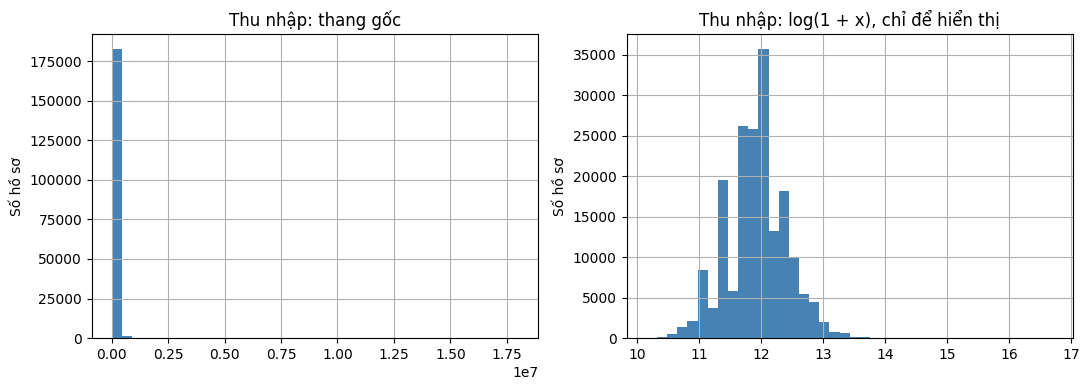

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
train['AMT_INCOME_TOTAL'].hist(bins=40, ax=axes[0], color='steelblue')
axes[0].set_title('Thu nhập: thang gốc')
np.log1p(train['AMT_INCOME_TOTAL']).hist(bins=40, ax=axes[1], color='steelblue')
axes[1].set_title('Thu nhập: log(1 + x), chỉ để hiển thị')
for ax in axes:
    ax.set_ylabel('Số hồ sơ')
plt.tight_layout()
plt.show()


In [21]:
history_money = history_results['money']
display(history_money)


,column,min,max,negative_n,zero_n,table
0,AMT_CREDIT_SUM,0.000,1.701000e+08,0,33386,bureau
1,AMT_CREDIT_SUM_DEBT,-3109510.980,1.701000e+08,5027,519013,bureau
2,AMT_CREDIT_SUM_OVERDUE,0.000,3.756681e+06,0,877636,bureau
3,AMT_CREDIT,0.000,4.104351e+06,0,166173,previous_application
4,AMT_ANNUITY,0.000,4.180581e+05,0,752,previous_application
5,AMT_APPLICATION,0.000,4.185000e+06,0,195248,previous_application
6,AMT_BALANCE,-420250.185,1.354829e+06,1190,1074040,credit_card_balance
7,AMT_PAYMENT_CURRENT,0.000,4.289207e+06,0,197448,credit_card_balance
8,AMT_CREDIT_LIMIT_ACTUAL,0.000,1.350000e+06,0,376847,credit_card_balance
9,AMT_INSTALMENT,0.000,3.473583e+06,0,87,installments_payments


Thu nhập train nằm trong khoảng **25.650–18.000.090** và có phân phối lệch phải; annuity thiếu **8 hồ sơ**. Các giá trị lớn cần kiểm chứng nhưng chưa đủ căn cứ để gọi là sai. Lịch sử có **5.027 dòng `AMT_CREDIT_SUM_DEBT` âm** và **1.190 dòng `AMT_BALANCE` âm**; cần xác minh ý nghĩa nghiệp vụ, không mặc định thay bằng 0.

Biểu đồ log chỉ hỗ trợ quan sát đuôi phân phối; notebook chưa biến đổi, cắt ngọn hoặc sửa các giá trị này.


<a id="muc-04-2"></a>

### 04.2. Sentinel và giá trị đặc biệt
đếm giá trị 365243 trong các trường thời gian; đối chiếu DAYS_EMPLOYED theo loại thu nhập để tránh diễn giải giá trị đặc biệt thành thâm niên thực tế. Lưu các thống kê thời gian để kiểm tra tiếp ở mục 05.1.

In [22]:
time_checks = history_results['time_checks']
sentinel_rows = time_checks['sentinel_n'] > 0
display(time_checks.loc[sentinel_rows, ['table', 'column', 'rows', 'sentinel_n']])


,table,column,rows,sentinel_n
1,application_train,DAYS_EMPLOYED,184506,33122
11,previous_application,DAYS_FIRST_DRAWING,848478,479818
12,previous_application,DAYS_FIRST_DUE,848478,20516
13,previous_application,DAYS_LAST_DUE_1ST_VERSION,848478,47529
14,previous_application,DAYS_LAST_DUE,848478,108646
15,previous_application,DAYS_TERMINATION,848478,116535


**Sentinel thâm niên theo loại thu nhập**

In [23]:
employment_groups = pd.crosstab(train['NAME_INCOME_TYPE'], (train['DAYS_EMPLOYED'] == 365243))
employment_groups = employment_groups.reindex(columns=[False, True], fill_value=0)
employment_groups.columns = ['other_value_n', 'sentinel_365243_n']
display(employment_groups)


,other_value_n,sentinel_365243_n
NAME_INCOME_TYPE,,
Businessman,6,0
Commercial associate,42924,0
Maternity leave,2,0
Pensioner,5,33111
State servant,13158,0
Student,7,0
Unemployed,0,11
Working,95282,0


**Đọc lại định nghĩa DAYS_EMPLOYED**

In [24]:
dictionary = pd.read_csv(ROOT / 'data/metadata/HomeCredit_columns_description.csv', encoding='latin1')
dictionary.columns = dictionary.columns.str.strip()
display(dictionary.loc[(dictionary['Row'].str.strip() == 'DAYS_EMPLOYED'),
                       ['Table', 'Row', 'Description']])


,Table,Row,Description
18,application_{train|test}.csv,DAYS_EMPLOYED,How many days before the application the perso...


`DAYS_EMPLOYED = 365243` xuất hiện ở **33.122 hồ sơ train**; sentinel cũng xuất hiện trong năm trường ngày của `previous_application`. Từ điển mô tả ngày tương đối nhưng chưa giải thích đầy đủ mã này. Cần giữ cờ nhận diện và xác minh trước khi thay bằng missing; không xem mọi ngày âm hoặc bằng 0 là thiếu.


<a id="muc-04-3"></a>

### 04.3. Biến phân loại: nhóm hiếm và mã đặc biệt
thống kê toàn bộ mức của biến phân loại application, tìm nhóm ít quan sát và mã XNA/XAP; xem riêng STATUS của bureau_balance để không mã hóa nhầm X/C thành mức quá hạn.

**Tần suất giá trị phân loại trong hồ sơ**

In [25]:
category_rows = []
for column in train.select_dtypes(include=['object', 'string', 'category']).columns:
    counts = train[column].value_counts(dropna=False).rename_axis('value').reset_index(name='n')
    counts['column'] = column
    counts['pct'] = counts['n'] / len(train) * 100
    category_rows.append(counts)
application_categories = pd.concat(category_rows, ignore_index=True)
display(application_categories.loc[
    (application_categories['n'] < 100) |
    application_categories['value'].isin(['XNA', 'XAP'])
])


,value,n,column,pct
4,XNA,1,CODE_GENDER,0.000542
21,Unemployed,11,NAME_INCOME_TYPE,0.005962
22,Student,7,NAME_INCOME_TYPE,0.003794
23,Businessman,6,NAME_INCOME_TYPE,0.003252
24,Maternity leave,2,NAME_INCOME_TYPE,0.001084
29,Academic degree,90,NAME_EDUCATION_TYPE,0.048779
35,Unknown,2,NAME_FAMILY_STATUS,0.001084
69,XNA,33122,ORGANIZATION_TYPE,17.951720
119,Industry: type 6,67,ORGANIZATION_TYPE,0.036313
120,Industry: type 10,63,ORGANIZATION_TYPE,0.034145


**Tần suất giá trị phân loại trong lịch sử**

In [26]:
history_categories = history_results['categories']
display(history_categories)


,value,n,table,column
0,C,4235831.0,bureau_balance,STATUS
1,0,2785464.0,bureau_balance,STATUS
2,X,1717508.0,bureau_balance,STATUS
3,1,93440.0,bureau_balance,STATUS
4,5,24765.0,bureau_balance,STATUS
5,2,9346.0,bureau_balance,STATUS
6,3,3556.0,bureau_balance,STATUS
7,4,2350.0,bureau_balance,STATUS
8,Approved,532100.0,previous_application,NAME_CONTRACT_STATUS
9,Canceled,155838.0,previous_application,NAME_CONTRACT_STATUS


**Đọc định nghĩa trạng thái khoản vay**

In [27]:
status_description = dictionary['Row'].str.strip() == 'STATUS'
display(dictionary.loc[status_description, ['Table', 'Row', 'Description']])


,Table,Row,Description
141,bureau_balance.csv,STATUS,Status of Credit Bureau loan during the month ...


Một số nhóm phân loại rất nhỏ: Businessman **6**, Maternity leave **2**, Student **7**, Unemployed **11** hồ sơ train; `CODE_GENDER = XNA` có **1** hồ sơ. Khi xây dựng pipeline, cần xử lý theo ý nghĩa của từng trường và tính đến mức mới.

Trong `bureau_balance`, `X` nghĩa là không rõ trạng thái, `C` là khoản vay đã đóng, còn `0–5` là các mã trạng thái riêng. Không xem các mã này như thang trễ hạn tăng đều; ý nghĩa `XNA/XAP` cũng tùy trường.


<a id="muc-04-4"></a>

### 04.4. Ngoại lai đơn biến và đa biến

| Loại | Đặc điểm | Cách nhận diện và điều kiện sử dụng |
|---|---|---|
| Đơn biến — Univariate | Cực đoan khi xét riêng một biến | Boxplot/IQR; Z-score có thể tham khảo nhưng diễn giải ngưỡng 3 độ lệch chuẩn thường gắn với phân phối gần chuẩn |
| Đa biến — Multivariate | Tổ hợp nhiều biến khác biệt, dù từng biến riêng có thể không cực đoan | Scatter plot để xem cấu trúc kết hợp; Mahalanobis xét hiệp phương sai nhưng cần đánh giá phân phối, độ ổn định của ma trận và ngưỡng trước khi áp dụng |

Phần này dùng IQR với Q1/Q3 là phân vị 25%/75%, hai hàng rào Q1 − 1,5 × IQR và Q3 + 1,5 × IQR. Đây là quy tắc mô tả, không chứng minh giá trị nằm ngoài hàng rào là lỗi. Phân biệt đơn/đa biến và lựa chọn phương pháp dựa *Python Data Analysis*, chương 7, tr. 287–294. Các đồ thị dùng thang log để dễ quan sát, không biến đổi dữ liệu nguồn.

Phần dưới bổ sung đối chiếu theo `NAME_CONTRACT_TYPE` và xem các khoản tiền cùng nhau. Đây là lựa chọn phân tích cho dữ liệu Home Credit, không phải ngưỡng phê duyệt khoản vay.

<a id="muc-04-4-1"></a>

#### 04.4.1. IQR và boxplot toàn train
tính hai hàng rào IQR, số lượng và tỷ lệ vượt rào cho bốn biến tiền trên toàn train; dùng kết quả này làm đường cơ sở để đối chiếu với từng loại khoản vay.

**Tính hàng rào IQR và tỷ lệ ngoài hàng rào**

In [28]:
q1 = train[money_columns].quantile(.25)
q3 = train[money_columns].quantile(.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
iqr_flags = (train[money_columns] < lower_fence) | (train[money_columns] > upper_fence)
iqr_summary = pd.DataFrame({
    'observed_n': train[money_columns].count(),
    'q1': q1, 'q3': q3, 'iqr': iqr,
    'lower_fence': lower_fence, 'upper_fence': upper_fence,
    'outside_fence_n': iqr_flags.sum()
})
iqr_summary['outside_fence_pct'] = iqr_summary['outside_fence_n'] / iqr_summary['observed_n'] * 100
display(iqr_summary)


,observed_n,q1,q3,iqr,lower_fence,upper_fence,outside_fence_n,outside_fence_pct
AMT_INCOME_TOTAL,184506,112500.0,202500.0,90000.0,-22500.0,337500.0,8445,4.577087
AMT_CREDIT,184506,270000.0,808650.0,538650.0,-537975.0,1616625.0,3978,2.156027
AMT_ANNUITY,184498,16524.0,34596.0,18072.0,-10584.0,61704.0,4526,2.453143
AMT_GOODS_PRICE,184352,238500.0,679500.0,441000.0,-423000.0,1341000.0,8912,4.834230


**Xem phân phối tiền trên thang log**

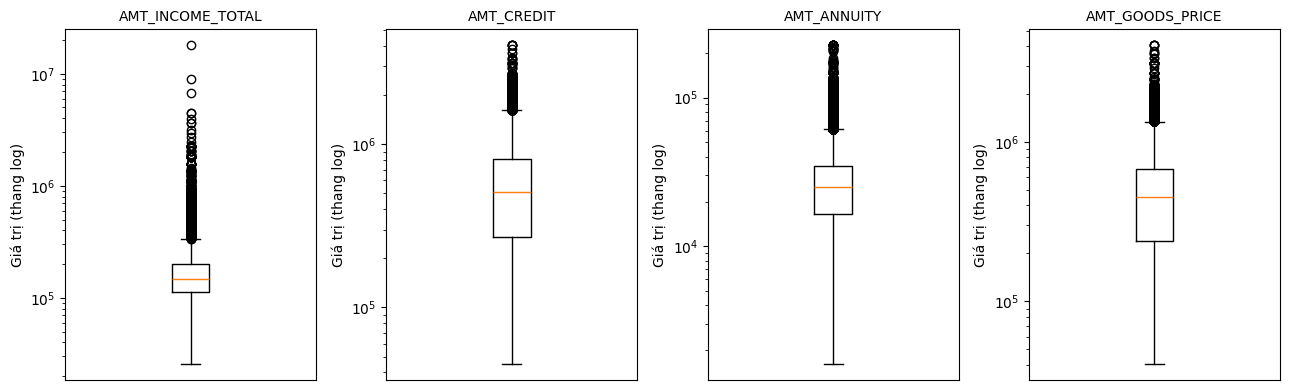

In [29]:
fig, axes = plt.subplots(1, 4, figsize=(13, 4))
for column, ax in zip(money_columns, axes):
    ax.boxplot(train[column].dropna(), showfliers=True)
    ax.set_yscale('log')
    ax.set_title(column, fontsize=10)
    ax.set_xticks([])
    ax.set_ylabel('Giá trị (thang log)')
plt.tight_layout()
plt.show()


Ngoài hàng rào IQR có **8.445 giá trị thu nhập (4,58%)**, **3.978 credit (2,16%)**, **4.526 annuity (2,45%)** và **8.912 goods price (4,83%)**. Mẫu số là số giá trị không thiếu riêng từng cột; các cờ có thể giao nhau nên không cộng trực tiếp thành số hồ sơ duy nhất. Boxplot cho thấy đuôi phải dài; vượt hàng rào là trường hợp cần xem xét, chưa phải kết luận lỗi.


<a id="muc-04-4-2"></a>

#### 04.4.2. Rà soát hồ sơ cực đoan
xem năm hồ sơ có giá trị thấp nhất và năm hồ sơ cao nhất của từng biến tiền, kèm loại khoản vay, loại thu nhập, nghề nghiệp, tuổi và các khoản tiền còn lại. Đối chiếu cờ IQR để phân biệt giá trị ở đầu phân phối với trường hợp vượt hàng rào.

Danh sách là mẫu rà soát có chủ đích, không đại diện cho toàn bộ hồ sơ vượt IQR. Chỉ đối chiếu thông tin có trong dữ liệu; chưa thể xác minh với chứng từ hoặc hệ thống gốc.

In [30]:
context_columns = ['SK_ID_CURR', 'NAME_CONTRACT_TYPE', 'NAME_INCOME_TYPE',
                   'OCCUPATION_TYPE'] + money_columns
extreme_parts = []
for column in money_columns:
    ordered = train.loc[train[column].notna()].sort_values([column, 'SK_ID_CURR'])
    for tail, selected in [('Thấp nhất', ordered.head(5)),
                           ('Cao nhất', ordered.tail(5).sort_values(column, ascending=False))]:
        examples = selected.loc[:, context_columns].copy()
        examples['age_years'] = (-selected['DAYS_BIRTH'] / 365.25).round(1)
        examples['checked_column'] = column
        examples['tail'] = tail
        examples['global_iqr_flag'] = iqr_flags.loc[selected.index, column]
        extreme_parts.append(examples)
        print(column, '-', tail)
        display(examples[context_columns + ['age_years', 'global_iqr_flag']])

extreme_records = pd.concat(extreme_parts, ignore_index=True)
print('Số dòng minh họa:', len(extreme_records))
print('Số hồ sơ duy nhất:', extreme_records['SK_ID_CURR'].nunique())
del ordered, selected, examples


AMT_INCOME_TOTAL - Thấp nhất


,SK_ID_CURR,NAME_CONTRACT_TYPE,NAME_INCOME_TYPE,OCCUPATION_TYPE,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,age_years,global_iqr_flag
1023,101965,Cash loans,Working,Cleaning staff,25650.0,158148.0,5809.5,103500.0,48.8,False
111888,316377,Cash loans,Pensioner,NaN,26100.0,54000.0,5391.0,54000.0,58.8,False
147519,384810,Cash loans,Pensioner,NaN,26100.0,173092.5,12438.0,157500.0,57.2,False
105159,303289,Cash loans,Unemployed,NaN,26550.0,571500.0,16281.0,571500.0,55.3,False
1887,103644,Cash loans,Working,Cleaning staff,27000.0,101880.0,10075.5,90000.0,38.3,False


AMT_INCOME_TOTAL - Cao nhất


,SK_ID_CURR,NAME_CONTRACT_TYPE,NAME_INCOME_TYPE,OCCUPATION_TYPE,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,age_years,global_iqr_flag
122091,336147,Cash loans,Commercial associate,NaN,18000090.0,675000.0,69295.5,675000.0,43.0,True
46701,190160,Cash loans,Working,Managers,9000000.0,1431531.0,132601.5,1377000.0,45.0,True
78554,252084,Cash loans,Working,Laborers,6750000.0,790830.0,52978.5,675000.0,53.0,True
61719,219563,Revolving loans,Working,Managers,4500000.0,2250000.0,225000.0,2250000.0,29.5,True
122610,337151,Cash loans,Working,Managers,4500000.0,450000.0,47749.5,450000.0,50.5,True


AMT_CREDIT - Thấp nhất


,SK_ID_CURR,NAME_CONTRACT_TYPE,NAME_INCOME_TYPE,OCCUPATION_TYPE,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,age_years,global_iqr_flag
3524,106941,Cash loans,Working,Cleaning staff,67500.0,45000.0,4725.0,45000.0,45.8,False
3935,107678,Cash loans,Working,Laborers,126000.0,45000.0,5206.5,45000.0,24.5,False
4155,108074,Cash loans,Working,NaN,67500.0,45000.0,4774.5,45000.0,35.2,False
5564,110765,Cash loans,Commercial associate,Sales staff,135000.0,45000.0,4207.5,45000.0,23.5,False
7986,115599,Cash loans,Working,Sales staff,90000.0,45000.0,4450.5,45000.0,37.5,False


... (7 outputs left out)

,SK_ID_CURR,NAME_CONTRACT_TYPE,NAME_INCOME_TYPE,OCCUPATION_TYPE,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,age_years,global_iqr_flag
179149,445866,Cash loans,Working,Low-skill Laborers,135000.0,48519.0,4576.5,40500.0,35.3,False
59,100127,Cash loans,Pensioner,NaN,112500.0,52128.0,5341.5,45000.0,58.4,False
282,100556,Cash loans,Pensioner,NaN,58500.0,50940.0,4959.0,45000.0,62.2,False
511,100966,Cash loans,Working,Cooking staff,63000.0,47970.0,4873.5,45000.0,36.9,False
1134,102164,Cash loans,Pensioner,NaN,121500.0,50940.0,2974.5,45000.0,65.1,False


AMT_GOODS_PRICE - Cao nhất


,SK_ID_CURR,NAME_CONTRACT_TYPE,NAME_INCOME_TYPE,OCCUPATION_TYPE,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,age_years,global_iqr_flag
8883,117337,Cash loans,Commercial associate,Managers,760846.5,4050000.0,146002.5,4050000.0,35.0,True
71764,238782,Cash loans,Commercial associate,Managers,931365.0,4050000.0,102514.5,4050000.0,34.3,True
66179,228135,Cash loans,Commercial associate,Managers,864900.0,4050000.0,102384.0,4050000.0,40.9,True
172649,433294,Cash loans,Commercial associate,Accountants,405000.0,4050000.0,102514.5,4050000.0,31.1,True
57309,210956,Cash loans,Working,Managers,430650.0,4031032.5,102033.0,3712500.0,45.1,True


Số dòng minh họa: 40
Số hồ sơ duy nhất: 35


**40 dòng minh họa thuộc 35 hồ sơ duy nhất**; cả 20 dòng minh họa phía thấp không vượt hàng rào IQR toàn train. Hồ sơ **336147** có thu nhập **18.000.090**, credit **675.000**, annuity **69.295,5**, thuộc Cash loans/Commercial associate nhưng chưa có nghề nghiệp. Hồ sơ **252084** ghi nghề Laborers với thu nhập **6.750.000**; tổ hợp này cần đối chiếu nguồn khai báo, chưa đủ căn cứ kết luận sai.

Năm dòng annuity cao nhất được chọn đều là **225.000** ở Revolving loans, cùng credit **2.250.000** nhưng mức thu nhập khác nhau. Sự lặp lại cần được xem cùng điều khoản sản phẩm; chưa chứng minh đây là lỗi hoặc mức trả nợ thực tế giống nhau. Mẫu minh họa chọn theo cực trị và chỉ lấy năm hồ sơ mỗi phía, không đại diện toàn bộ cờ IQR; chưa xác minh được với chứng từ hoặc hệ thống gốc.

<a id="muc-04-4-3"></a>

#### 04.4.3. Đối chiếu theo loại khoản vay
tính lại IQR trong từng nhóm Cash loans và Revolving loans trên train, so sánh số cờ với hàng rào toàn train trên chính các hồ sơ đó. Đếm trường hợp chỉ vượt rào toàn train hoặc chỉ vượt rào trong nhóm, rồi đối chiếu boxplot hai sản phẩm.

Hai cách đặt hàng rào trả lời hai câu hỏi khác nhau: cực đoan so với toàn train và cực đoan so với cùng loại khoản vay. Không dùng số cờ ít hơn làm tiêu chí chọn cách xử lý.

In [31]:
product_iqr_parts = []
for product, group in train.groupby('NAME_CONTRACT_TYPE', observed=True):
    group_q1 = group[money_columns].quantile(.25)
    group_q3 = group[money_columns].quantile(.75)
    group_iqr = group_q3 - group_q1
    group_lower = group_q1 - 1.5 * group_iqr
    group_upper = group_q3 + 1.5 * group_iqr
    group_flags = (group[money_columns] < group_lower) | (group[money_columns] > group_upper)
    global_flags = iqr_flags.loc[group.index]

    summary = pd.DataFrame({
        'group_n': len(group),
        'observed_n': group[money_columns].count(),
        'missing_n': group[money_columns].isna().sum(),
        'q1': group_q1, 'q3': group_q3, 'iqr': group_iqr,
        'lower_fence': group_lower, 'upper_fence': group_upper,
        'global_flag_n': global_flags.sum(),
        'group_flag_n': group_flags.sum(),
        'both_flag_n': (global_flags & group_flags).sum(),
        'global_only_n': (global_flags & ~group_flags).sum(),
        'group_only_n': (group_flags & ~global_flags).sum()
    })
    summary['global_flag_pct'] = summary['global_flag_n'] / summary['observed_n'] * 100
    summary['group_flag_pct'] = summary['group_flag_n'] / summary['observed_n'] * 100
    summary['NAME_CONTRACT_TYPE'] = product
    product_iqr_parts.append(summary.rename_axis('column').reset_index())

product_iqr = pd.concat(product_iqr_parts, ignore_index=True)
display(product_iqr[['NAME_CONTRACT_TYPE', 'column', 'observed_n', 'global_flag_pct',
                     'group_flag_pct', 'global_only_n', 'group_only_n']])


,NAME_CONTRACT_TYPE,column,observed_n,global_flag_pct,group_flag_pct,global_only_n,group_only_n
0,Cash loans,AMT_INCOME_TOTAL,166910,4.494638,4.494638,0,0
1,Cash loans,AMT_CREDIT,166910,2.358756,2.271284,146,0
2,Cash loans,AMT_ANNUITY,166902,2.503265,2.378042,209,0
3,Cash loans,AMT_GOODS_PRICE,166910,5.169253,2.815889,3928,0
4,Revolving loans,AMT_INCOME_TOTAL,17596,5.359173,5.836554,0,84
5,Revolving loans,AMT_CREDIT,17596,0.233008,8.274608,0,1415
6,Revolving loans,AMT_ANNUITY,17596,1.977722,8.280291,0,1109
7,Revolving loans,AMT_GOODS_PRICE,17442,1.628254,8.433666,0,1187


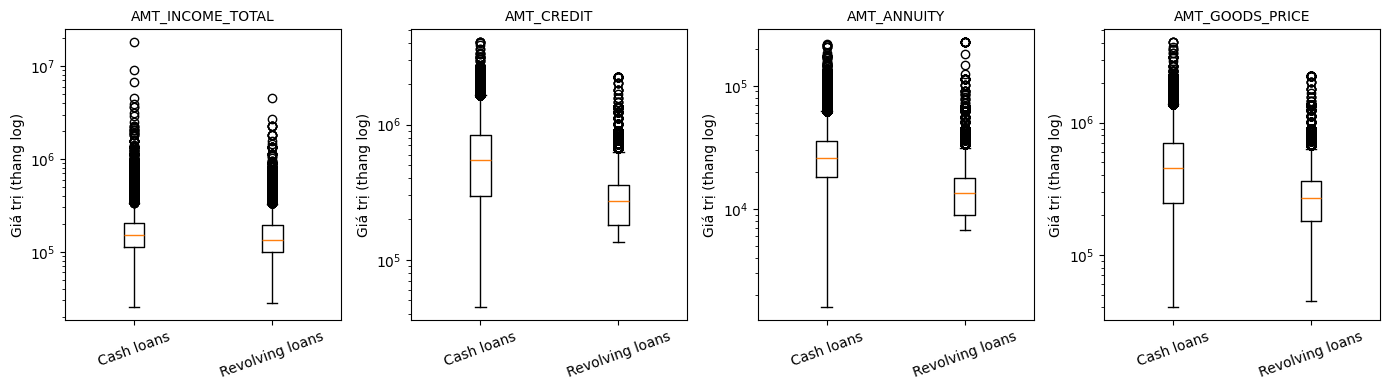

In [32]:
products = sorted(train['NAME_CONTRACT_TYPE'].dropna().unique())
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for column, ax in zip(money_columns, axes):
    values = []
    for product in products:
        product_rows = train['NAME_CONTRACT_TYPE'] == product
        values.append(train.loc[product_rows, column].dropna())
    ax.boxplot(values, tick_labels=products, showfliers=True)
    ax.set_yscale('log')
    ax.set_title(column, fontsize=10)
    ax.set_ylabel('Giá trị (thang log)')
    ax.tick_params(axis='x', labelrotation=20)
plt.tight_layout()
plt.show()


Train gồm **166.910 Cash loans** và **17.596 Revolving loans**. Với credit ở Revolving loans, hàng rào trên giảm từ **1.616.625** của toàn train xuống **630.000** trong nhóm: số cờ tăng từ **41 (0,23%)** lên **1.456 (8,27%)**, gồm **1.415 hồ sơ chỉ bị gắn cờ khi so trong nhóm**. Annuity của nhóm này có số cờ tăng từ **348 (1,98%)** lên **1.457 (8,28%)**.

Ở Cash loans, số cờ goods price giảm từ **8.628 (5,17%)** xuống **4.700 (2,82%)** khi dùng hàng rào trong nhóm. Các thay đổi phản ánh nhóm tham chiếu khác nhau, chưa cho biết cách nào xác định lỗi tốt hơn. Cần giữ thông tin sản phẩm khi xem hồ sơ cực đoan; chưa dùng các hàng rào làm ngưỡng cắt dữ liệu hoặc ngưỡng phê duyệt.

<a id="muc-04-4-4"></a>

#### 04.4.4. Quan hệ giữa thu nhập và khoản vay
xem ba cặp thu nhập–credit, thu nhập–annuity và credit–annuity riêng cho từng loại khoản vay; đánh dấu lại các hồ sơ minh họa ở mục 04.4.2. Ghi số cặp đủ dữ liệu và số cặp không hiển thị để tránh diễn giải đồ thị vượt phạm vi quan sát.

Theo từ điển, `AMT_INCOME_TOTAL` là thu nhập khách hàng, `AMT_CREDIT` là số tiền khoản vay và `AMT_ANNUITY` là annuity. Chưa xác minh đầy đủ kỳ đo, thu nhập ròng/gộp hoặc các nghĩa vụ khác nên không quy đổi tỷ số thành DTI chuẩn, không mặc định credit là hạn mức/EAD. Vòng tròn đỏ chỉ là hồ sơ minh họa đã chọn, không phải nhãn ngoại lai đa biến hay nhãn rủi ro.

**Vẽ mối liên hệ các khoản tiền theo loại vay**

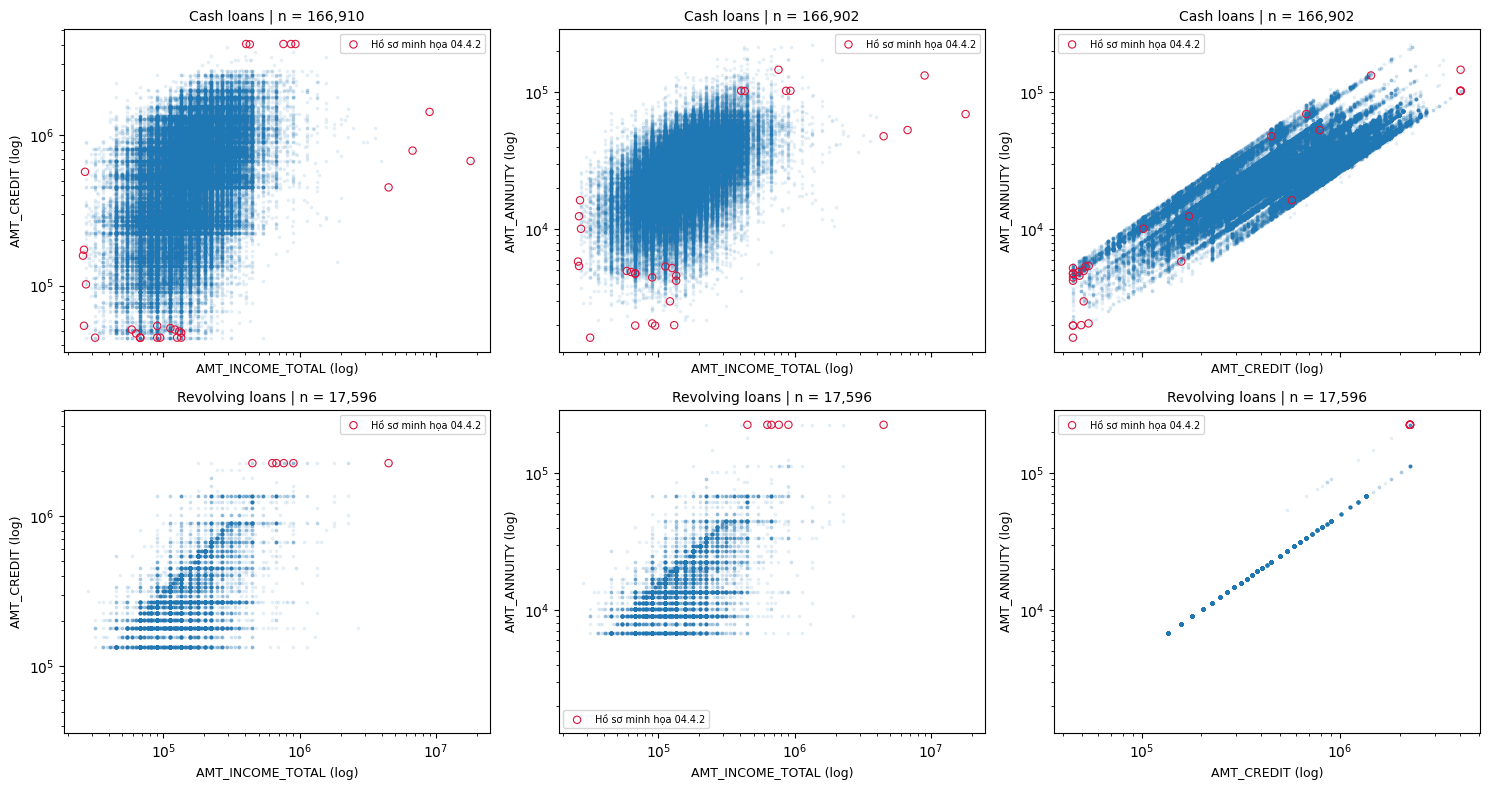

In [33]:
money_pairs = [('AMT_INCOME_TOTAL', 'AMT_CREDIT'),
               ('AMT_INCOME_TOTAL', 'AMT_ANNUITY'),
               ('AMT_CREDIT', 'AMT_ANNUITY')]
pair_scope_rows = []
fig, axes = plt.subplots(len(products), 3, figsize=(15, 8), sharex='col', sharey='col')
for row, product in enumerate(products):
    group = train.loc[(train['NAME_CONTRACT_TYPE'] == product)]
    for col, (x, y) in enumerate(money_pairs):
        complete = group[[x, y]].notna().all(axis=1)
        positive = complete & (group[x] > 0) & (group[y] > 0)
        example = positive & group['SK_ID_CURR'].isin(extreme_records['SK_ID_CURR'])
        ax = axes[row, col]
        ax.scatter(group.loc[positive, x], group.loc[positive, y], s=3, alpha=.08)
        ax.scatter(group.loc[example, x], group.loc[example, y], s=28,
                   facecolors='none', edgecolors='crimson', linewidths=.8,
                   label='Hồ sơ minh họa 04.4.2')
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_xlabel(x + ' (log)', fontsize=9)
        ax.set_ylabel(y + ' (log)', fontsize=9)
        ax.set_title(product + ' | n = ' + f'{positive.sum():,}', fontsize=10)
        ax.legend(fontsize=7)
        pair_scope_rows.append({
            'NAME_CONTRACT_TYPE': product, 'x': x, 'y': y,
            'group_n': len(group), 'complete_n': int(complete.sum()),
            'missing_pair_n': int((~complete).sum()),
            'nonpositive_pair_n': int((complete & ~positive).sum()),
            'plotted_n': int(positive.sum()), 'example_n': int(example.sum())
        })
plt.tight_layout()
plt.show()


**Đọc phạm vi quan sát của từng hình**

In [34]:
pair_scope = pd.DataFrame(pair_scope_rows)
display(pair_scope)


,NAME_CONTRACT_TYPE,x,y,group_n,complete_n,missing_pair_n,nonpositive_pair_n,plotted_n,example_n
0,Cash loans,AMT_INCOME_TOTAL,AMT_CREDIT,166910,166910,0,0,166910,29
1,Cash loans,AMT_INCOME_TOTAL,AMT_ANNUITY,166910,166902,8,0,166902,29
2,Cash loans,AMT_CREDIT,AMT_ANNUITY,166910,166902,8,0,166902,29
3,Revolving loans,AMT_INCOME_TOTAL,AMT_CREDIT,17596,17596,0,0,17596,6
4,Revolving loans,AMT_INCOME_TOTAL,AMT_ANNUITY,17596,17596,0,0,17596,6
5,Revolving loans,AMT_CREDIT,AMT_ANNUITY,17596,17596,0,0,17596,6


Cặp thu nhập–credit hiển thị đủ **184.506 hồ sơ**; hai cặp có annuity hiển thị **184.498 hồ sơ**, do **8 hồ sơ Cash loans thiếu annuity**. Không có cặp đủ dữ liệu nhưng không dương phải bỏ khỏi trục log. Mỗi cặp hiển thị lại đủ **35 hồ sơ minh họa**, gồm **29 Cash loans và 6 Revolving loans**.

Đồ thị credit–annuity cho thấy Cash loans tạo nhiều dải, còn Revolving loans tập trung sát một dải chính và một số điểm tách khỏi dải. Các cặp có thu nhập giúp đặt hồ sơ cực trị cạnh các khoản tiền liên quan, nhưng chưa giải thích nguyên nhân hoặc khả năng trả nợ. Vòng tròn đỏ chỉ đánh dấu ví dụ đã chọn; scatter chưa tạo ra nhãn ngoại lai đa biến định lượng.

### Kết luận mục 04

Ngoài hàng rào IQR có **8.445 giá trị thu nhập (4,58%)**, **3.978 credit (2,16%)**, **4.526 annuity (2,45%)** và **8.912 goods price (4,83%)**. Các cờ có thể giao nhau; so sánh theo sản phẩm cũng cho thấy kết quả phụ thuộc nhóm tham chiếu. Các kiểm tra xác định phạm vi cần rà soát nhưng không tự động sửa dữ liệu. Trước khi biến đổi sentinel, số âm hoặc giá trị vượt IQR, cần xác minh định nghĩa, kỳ đo và điều kiện sản phẩm.


<a id="muc-05"></a>

<a id="part-5"></a>

## 05. Kiểm tra logic và tính nhất quán

<a id="muc-05-1"></a>

### 05.1. Thời điểm thông tin
xem ngày dương sau khi tách sentinel, tháng 0 và tháng dương; phân biệt lịch dự kiến với sự kiện thực tế để nhận diện trường cần xác minh tính sẵn có tại thời điểm dự báo.

In [35]:
display(time_checks[['table', 'column', 'missing_n', 'sentinel_n',
                     'positive_excluding_sentinel_n', 'zero_n',
                     'min_excluding_sentinel', 'max_excluding_sentinel']])
positive_dates = time_checks.loc[(time_checks['positive_excluding_sentinel_n'] > 0)]
display(positive_dates[['table', 'column', 'positive_excluding_sentinel_n']])
display(time_checks.loc[(time_checks['column'] == 'MONTHS_BALANCE'),
                        ['table', 'zero_n', 'positive_excluding_sentinel_n',
                         'min_excluding_sentinel', 'max_excluding_sentinel']])


,table,column,missing_n,sentinel_n,positive_excluding_sentinel_n,zero_n,min_excluding_sentinel,max_excluding_sentinel
0,application_train,DAYS_BIRTH,0,0,0,0,-25229.0,-7489.0
1,application_train,DAYS_EMPLOYED,0,33122,0,1,-17912.0,0.0
2,application_train,DAYS_REGISTRATION,0,0,0,46,-24672.0,0.0
3,application_train,DAYS_ID_PUBLISH,0,0,0,12,-7197.0,0.0
4,application_train,DAYS_LAST_PHONE_CHANGE,1,0,0,22548,-4292.0,0.0
5,bureau,DAYS_CREDIT,0,0,0,2,-2922.0,0.0
6,bureau,DAYS_CREDIT_ENDDATE,53475,0,308649,433,-42060.0,31199.0
7,bureau,DAYS_ENDDATE_FACT,327200,0,0,39,-42023.0,0.0
8,bureau,DAYS_CREDIT_UPDATE,0,0,11,292,-41947.0,372.0
9,bureau_balance,MONTHS_BALANCE,0,0,0,208201,-96.0,0.0


,table,column,positive_excluding_sentinel_n
6,bureau,DAYS_CREDIT_ENDDATE,308649
8,bureau,DAYS_CREDIT_UPDATE,11
13,previous_application,DAYS_LAST_DUE_1ST_VERSION,116825


,table,zero_n,positive_excluding_sentinel_n,min_excluding_sentinel,max_excluding_sentinel
9,bureau_balance,208201,0,-96.0,0.0
16,pos_cash_balance,0,0,-96.0,-1.0
17,credit_card_balance,0,0,-96.0,-1.0


Sau khi tách sentinel, có **308.649 dòng `DAYS_CREDIT_ENDDATE` dương**, **116.825 dòng `DAYS_LAST_DUE_1ST_VERSION` dương** và **11 dòng `DAYS_CREDIT_UPDATE` dương** trong lịch sử train. Hai trường đầu là lịch dự kiến nên ngày tương lai chưa đủ để kết luận leakage; trường cập nhật thực tế cần xác minh rõ hơn.

`MONTHS_BALANCE = 0` xuất hiện ở **208.201 dòng `bureau_balance`**; không có tháng dương trong ba bảng snapshot. Cần xác minh thời điểm snapshot tháng 0 so với đơn vay trước khi dùng các trường này để tạo đặc trưng.


<a id="muc-05-2"></a>

### 05.2. Thanh toán ở cấp bản ghi
đếm dòng thanh toán sau ngày đến hạn, thiếu ngày thanh toán và số tiền một lần trả nhỏ hơn nghĩa vụ kỳ. Xem năm khóa kỳ lặp đã lấy ở mục 02.2, đối chiếu số tiền/ngày đến hạn và cộng các lần thanh toán trong từng kỳ mẫu.

**Đếm các dấu hiệu ở cấp dòng thanh toán**

In [36]:
payment_counts = history_results['payment_counts']
display(pd.DataFrame([payment_counts]))


,train_payment_rows,missing_payment_date_n,payment_after_due_n,payment_below_instalment_n
0,6959239,1563,597363,673729


**Xem các lần thanh toán trong cùng kỳ**

In [37]:
payment_sample = history_results['payment_sample']
payment_sample = payment_sample.sort_values(installment_key + ['DAYS_ENTRY_PAYMENT'])
display(payment_sample)


,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
3,1220449,136423,1.0,16,-61.0,-89.0,34717.500,2675.745
6,1220449,136423,1.0,16,-61.0,-58.0,34717.500,32041.755
0,1410565,197687,1.0,1,-1037.0,-1048.0,12514.050,12510.450
7,1410565,197687,1.0,1,-1037.0,-1029.0,12514.050,3.600
5,1840786,175114,1.0,11,-476.0,-503.0,21179.700,18.000
1,1840786,175114,1.0,11,-476.0,-474.0,21179.700,21161.700
8,1895324,131465,1.0,6,-1386.0,-1413.0,3229.065,16.200
2,1895324,131465,1.0,6,-1386.0,-1379.0,3229.065,3212.865
4,2726751,182114,1.0,20,-1066.0,-1091.0,10770.750,499.500
9,2726751,182114,1.0,20,-1066.0,-1059.0,10770.750,10271.250


**So sánh tiền đã trả với nghĩa vụ của kỳ**

In [38]:
period_sample = history_results['period_sample']
display(period_sample)


,SK_ID_PREV,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,payment_rows,obligation_values,due_date_values,obligation_first,payment_total,missing_payment_amount_n,missing_payment_date_n,last_payment_day
0,1220449,1.0,16,2,1,1,34717.500,34717.500,0,0,-58.0
1,1410565,1.0,1,2,1,1,12514.050,12514.050,0,0,-1029.0
2,1840786,1.0,11,2,1,1,21179.700,21179.700,0,0,-474.0
3,1895324,1.0,6,2,1,1,3229.065,3229.065,0,0,-1379.0
4,2726751,1.0,20,2,1,1,10770.750,10770.750,0,0,-1059.0


Trong **6.959.239 dòng thanh toán train**, có **597.363 dòng trả sau hạn**, **673.729 dòng có `AMT_PAYMENT` nhỏ hơn `AMT_INSTALMENT`** và **1.563 dòng thiếu ngày thanh toán**. Đây là số dòng, không phải số khoản vay hoặc số khách hàng vi phạm.

Các kỳ mẫu cho thấy một nghĩa vụ có thể có nhiều lần thanh toán. Khi tạo đặc trưng, cần cộng các lần trả và xem ngày hoàn tất nghĩa vụ, nhưng không cộng lặp `AMT_INSTALMENT` trên từng dòng. Năm kỳ mẫu không đại diện cho toàn bộ lịch sử.


<a id="muc-05-3"></a>

### 05.3. Thông tin khách hàng
đối chiếu ngày bắt đầu việc làm, ngày đổi giấy tờ và đăng ký với ngày sinh; đối chiếu số con với số thành viên gia đình và cờ sở hữu xe với tuổi xe. Chỉ kiểm tra trên hồ sơ train có đủ giá trị hợp lệ; loại sentinel khỏi phép so sánh ngày.

Ngày tương đối càng âm là càng xa trong quá khứ. Các mốc xảy ra trước ngày sinh là dấu hiệu mâu thuẫn thời gian. Các đối chiếu gia đình/xe chỉ là trường hợp cần xác minh định nghĩa và thời điểm ghi nhận, chưa phải lỗi chắc chắn.

In [39]:
birth_valid = (train['DAYS_BIRTH'] < 0)
employment_valid = birth_valid & (train['DAYS_EMPLOYED'] <= 0)
id_valid = birth_valid & (train['DAYS_ID_PUBLISH'] <= 0)
registration_valid = birth_valid & (train['DAYS_REGISTRATION'] <= 0)
family_valid = train[['CNT_CHILDREN', 'CNT_FAM_MEMBERS']].notna().all(axis=1)
car_valid = train['FLAG_OWN_CAR'].isin(['Y', 'N']) & train['OWN_CAR_AGE'].notna()

application_rules = pd.DataFrame({
    'Việc làm bắt đầu trước ngày sinh':
        (train['DAYS_EMPLOYED'] < train['DAYS_BIRTH']).where(employment_valid),
    'Ngày đổi giấy tờ trước ngày sinh':
        (train['DAYS_ID_PUBLISH'] < train['DAYS_BIRTH']).where(id_valid),
    'Ngày đổi đăng ký trước ngày sinh':
        (train['DAYS_REGISTRATION'] < train['DAYS_BIRTH']).where(registration_valid),
    'Số con lớn hơn số thành viên gia đình':
        (train['CNT_CHILDREN'] > train['CNT_FAM_MEMBERS']).where(family_valid),
    'Không sở hữu xe nhưng có tuổi xe':
        (train['FLAG_OWN_CAR'] == 'N').where(car_valid)
})
application_logic = pd.DataFrame({
    'eligible_n': application_rules.count(),
    'flagged_n': application_rules.sum().astype('int64')
})
application_logic['not_checked_n'] = len(train) - application_logic['eligible_n']
application_logic['flagged_pct'] = (
    application_logic['flagged_n'] / application_logic['eligible_n'].replace(0, np.nan) * 100
)
application_logic['interpretation'] = [
    'Dấu hiệu mâu thuẫn thời gian', 'Dấu hiệu mâu thuẫn thời gian',
    'Dấu hiệu mâu thuẫn thời gian', 'Cần xác minh định nghĩa gia đình',
    'Cần xác minh thời điểm ghi nhận xe'
]
display(application_logic)


,eligible_n,flagged_n,not_checked_n,flagged_pct,interpretation
Việc làm bắt đầu trước ngày sinh,151384,0,33122,0.0,Dấu hiệu mâu thuẫn thời gian
Ngày đổi giấy tờ trước ngày sinh,184506,0,0,0.0,Dấu hiệu mâu thuẫn thời gian
Ngày đổi đăng ký trước ngày sinh,184506,0,0,0.0,Dấu hiệu mâu thuẫn thời gian
Số con lớn hơn số thành viên gia đình,184504,0,2,0.0,Cần xác minh định nghĩa gia đình
Không sở hữu xe nhưng có tuổi xe,62577,0,121929,0.0,Cần xác minh thời điểm ghi nhận xe


In [40]:
application_logic_examples = []
example_columns = ['SK_ID_CURR', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_ID_PUBLISH',
                   'DAYS_REGISTRATION', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS',
                   'FLAG_OWN_CAR', 'OWN_CAR_AGE']
for rule in application_rules:
    is_flagged = application_rules[rule].fillna(False).astype(bool)
    examples = train.loc[is_flagged, example_columns].head(5).copy()
    if not examples.empty:
        examples.insert(0, 'rule', rule)
        application_logic_examples.append(examples)
        display(examples)


C:\Users\ASUS\AppData\Local\Temp\ipykernel_35004\3398261670.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  is_flagged = application_rules[rule].fillna(False).astype(bool)
C:\Users\ASUS\AppData\Local\Temp\ipykernel_35004\3398261670.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  is_flagged = application_rules[rule].fillna(False).astype(bool)
C:\Users\ASUS\AppData\Local\Temp\ipykernel_35004\3398261670.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer

Chưa phát hiện trường hợp bị gắn cờ trong năm quy tắc trên tập đủ điều kiện. Kiểm tra ngày bắt đầu việc làm có **151.384 hồ sơ hợp lệ**, tách **33.122 sentinel**; đối chiếu gia đình có **184.504 hồ sơ**, còn đối chiếu cờ xe/tuổi xe có **62.577 hồ sơ**. Thiếu thông tin không được tính là vượt qua kiểm tra.

Kết quả chỉ áp dụng cho các quy tắc đã kiểm tra, không khẳng định toàn bộ dữ liệu đều hợp lý. Tuổi xe cũng không được so trực tiếp với tuổi khách hàng vì xe có thể được sản xuất trước khi người sở hữu sinh ra.


<a id="muc-05-4"></a>

### 05.4. Ngày và số tiền trong lịch sử vay
kiểm tra thứ tự ngày của cùng khoản vay, đối chiếu dư nợ/quá hạn và hạn mức/số dư. Chỉ dùng lịch sử thuộc train có đủ hai giá trị; tách sentinel trước khi so sánh ngày. Ghi rõ số dòng có vấn đề và tối đa năm ví dụ cho từng quy tắc.

Số dư vượt hạn mức hoặc dư nợ lớn hơn số tiền vay có thể liên quan đến lãi, phí, thay đổi hạn mức hoặc cách ghi nhận. Ngày đến hạn cũng có thể chịu ảnh hưởng của thay đổi lịch trả nợ. Đây là tín hiệu cần xác minh, chưa đủ căn cứ xóa dòng hay kết luận khách hàng vi phạm.

In [41]:
history_logic = history_results['logic']
display(history_logic)


,rule,eligible_n,flagged_n,table,flagged_pct
0,Ngày kết thúc trước ngày xin vay,552658,6,bureau,0.001086
1,Ngày cập nhật trước ngày xin vay,879847,69,bureau,0.007842
2,Dư nợ lớn hơn số tiền tín dụng,740886,14962,bureau,2.019474
3,Tiền quá hạn lớn hơn dư nợ,740888,435,bureau,0.058713
4,Ngày đến hạn đầu trước ngày quyết định,491391,0,previous_application,0.000000
5,Ngày đến hạn cuối dự kiến trước kỳ đầu,460445,0,previous_application,0.000000
6,Số dư lớn hơn hạn mức cùng tháng,1939991,176568,credit_card_balance,9.101486


In [42]:
for examples in history_results['logic_examples']:
    display(examples)


,table,rule,SK_ID_CURR,SK_ID_BUREAU,DAYS_CREDIT,DAYS_ENDDATE_FACT,DAYS_CREDIT_UPDATE,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_OVERDUE
97529,bureau,Ngày kết thúc trước ngày xin vay,104463,6550986,-2340,-42023.0,-2196,225000.0,0.0,0.0
257330,bureau,Ngày kết thúc trước ngày xin vay,241703,6460615,-872,-2148.0,-19,2700000.0,0.0,0.0
331068,bureau,Ngày kết thúc trước ngày xin vay,324899,5019170,-1279,-2776.0,-1191,2250000.0,0.0,0.0
428770,bureau,Ngày kết thúc trước ngày xin vay,289566,5457839,-543,-564.0,-385,153000.0,0.0,0.0
594580,bureau,Ngày kết thúc trước ngày xin vay,316507,5520045,-887,-1062.0,-391,1350000.0,0.0,0.0


,table,rule,SK_ID_CURR,SK_ID_BUREAU,DAYS_CREDIT,DAYS_ENDDATE_FACT,DAYS_CREDIT_UPDATE,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_OVERDUE
1177,bureau,Ngày cập nhật trước ngày xin vay,219708,5716863,-331,-208.0,-41857,16414.245,0.0,0.0
14745,bureau,Ngày cập nhật trước ngày xin vay,380623,5800600,-281,NaN,-41906,225000.000,0.0,0.0
16288,bureau,Ngày cập nhật trước ngày xin vay,163624,5803704,-9,NaN,-16,45000.000,45805.5,0.0
30937,bureau,Ngày cập nhật trước ngày xin vay,214335,5238926,-311,NaN,-41934,90000.000,0.0,0.0
45568,bureau,Ngày cập nhật trước ngày xin vay,368921,5610302,-1095,-1095.0,-41878,36000.000,0.0,0.0


,table,rule,SK_ID_CURR,SK_ID_BUREAU,DAYS_CREDIT,DAYS_ENDDATE_FACT,DAYS_CREDIT_UPDATE,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_OVERDUE
47,bureau,Dư nợ lớn hơn số tiền tín dụng,242993,5714550,-382,NaN,-341,58500.0,59809.50,0.0
136,bureau,Dư nợ lớn hơn số tiền tín dụng,166034,5714701,-706,NaN,-4,459000.0,483534.00,0.0
220,bureau,Dư nợ lớn hơn số tiền tín dụng,198319,5714841,-126,NaN,-27,2466000.0,3479481.00,0.0
249,bureau,Dư nợ lớn hơn số tiền tín dụng,452711,5714930,-1288,NaN,-19,324000.0,329332.50,0.0
323,bureau,Dư nợ lớn hơn số tiền tín dụng,224915,5715137,-244,NaN,-81,0.0,73215.45,0.0


,table,rule,SK_ID_CURR,SK_ID_BUREAU,DAYS_CREDIT,DAYS_ENDDATE_FACT,DAYS_CREDIT_UPDATE,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_OVERDUE
1094,bureau,Tiền quá hạn lớn hơn dư nợ,295460,5716741,-926,NaN,-40,699300.0,0.0,36.00
1314,bureau,Tiền quá hạn lớn hơn dư nợ,398626,5717166,-1348,NaN,-40,585000.0,0.0,36.00
1324,bureau,Tiền quá hạn lớn hơn dư nợ,178283,5717190,-1492,NaN,-47,0.0,0.0,349428.06
3015,bureau,Tiền quá hạn lớn hơn dư nợ,100915,5722930,-362,NaN,-48,135000.0,4.5,409.50
3486,bureau,Tiền quá hạn lớn hơn dư nợ,436084,5723861,-987,NaN,-11,112095.0,0.0,172048.50


,table,rule,SK_ID_CURR,SK_ID_PREV,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL
0,credit_card_balance,Số dư lớn hơn hạn mức cùng tháng,363914,2582071,-1,63975.555,45000
1,credit_card_balance,Số dư lớn hơn hạn mức cùng tháng,337855,1389973,-4,236572.110,225000
5,credit_card_balance,Số dư lớn hơn hạn mức cùng tháng,231608,1189095,-4,452774.700,450000
6,credit_card_balance,Số dư lớn hơn hạn mức cùng tháng,217113,1683604,-1,68710.140,67500
8,credit_card_balance,Số dư lớn hơn hạn mức cùng tháng,105755,2021411,-5,464452.470,450000


Bureau có **6 dòng ngày kết thúc trước ngày xin vay** và **69 dòng ngày cập nhật trước ngày xin vay**, cần đối soát thứ tự thời gian. Hai quy tắc thứ tự ngày của `previous_application` không phát hiện mâu thuẫn trong các dòng đủ thông tin sau khi tách sentinel.

Các quan hệ số tiền có **14.962 dòng dư nợ lớn hơn số tiền tín dụng**, **435 dòng quá hạn lớn hơn dư nợ** và **176.568 dòng số dư lớn hơn hạn mức cùng tháng**. Đây là số dòng lịch sử; các nhóm có thể giao nhau nên không cộng thành số khách hàng vi phạm. Cần kiểm chứng lãi/phí, thay đổi hạn mức và phạm vi từng trường trước khi kết luận lỗi hoặc tạo đặc trưng từ các cờ này.


<a id="muc-05-5"></a>

### 05.5. Tính nhất quán trong cùng kỳ trả nợ
kiểm tra toàn bộ các kỳ có nhiều dòng thanh toán trên train, không chỉ năm kỳ mẫu ở mục 05.2. Trong cùng khóa kỳ, đếm trường hợp có nhiều số tiền nghĩa vụ hoặc nhiều ngày đến hạn; các lần trả vẫn được phép có số tiền/ngày thanh toán khác nhau.

In [43]:
period_logic = history_results['period_logic']
display(period_logic)
print('Số kỳ có nhiều dòng đã đối soát:', history_results['period_count'])

inconsistent_periods = history_results['inconsistent_periods']
if not inconsistent_periods.empty:
    display(inconsistent_periods.head(10))


,eligible_period_n,flagged_period_n,not_checked_period_n
Cùng kỳ có nhiều số tiền nghĩa vụ,333216,0,0
Cùng kỳ có nhiều ngày đến hạn,333216,0,0


Số kỳ có nhiều dòng đã đối soát: 333216


Đã đối soát toàn bộ **333.216 kỳ có nhiều dòng thanh toán** trên train; **0 kỳ có nhiều số tiền nghĩa vụ**, **0 kỳ có nhiều ngày đến hạn**. Có thể lấy một giá trị nghĩa vụ và hạn trả cho mỗi kỳ theo khóa đã kiểm tra, thay vì cộng lặp nghĩa vụ theo số lần trả. Kết quả chưa chứng minh khách hàng trả đủ hoặc đúng hạn; vẫn cần tổng hợp số tiền và ngày thanh toán như mục 05.2.

### Kết luận mục 05

Các kiểm tra phát hiện một số quan hệ ngày và tiền cần xác minh, đồng thời xác nhận nghĩa vụ và hạn trả nhất quán trong các kỳ lặp đã rà soát. Những dấu hiệu này là căn cứ thiết kế kiểm tra/đặc trưng tiếp theo, chưa phải kết luận dữ liệu sai hay nhãn rủi ro.


<a id="part-6"></a>

## 06. Xuất dữ liệu cho EDA

Mục này lưu các bảng bureau và POS đã tổng hợp theo hồ sơ để notebook EDA có thể đọc lại trong kernel riêng. Việc xuất giúp dùng lại kết quả đã kiểm tra mà không quét lại toàn bộ lịch sử.


In [44]:
EDA_DATA = ROOT / 'data/eda'
EDA_DATA.mkdir(parents=True, exist_ok=True)
history_results['bureau_by_app'].to_parquet(EDA_DATA / 'bureau_by_application.parquet')
history_results['pos_by_app'].to_parquet(EDA_DATA / 'pos_by_application.parquet')
history_results['eda_scope'].to_csv(EDA_DATA / 'history_scope.csv', index=False)
connector.disConnect()
print('Đã lưu hai bảng lịch sử cấp hồ sơ và phạm vi quan sát cho notebook 03.')

Đã lưu hai bảng lịch sử cấp hồ sơ và phạm vi quan sát cho notebook 03.


### Kết luận mục 06

Các bảng bureau và POS đã được lưu theo hồ sơ để EDA dùng lại. Kết quả kiểm tra chất lượng giúp phân biệt sentinel với thiếu thật, giữ đúng cấp kỳ trả nợ và rà soát thời điểm của nguồn lịch sử. Quan hệ giữa các đặc điểm này và TARGET được khảo sát ở notebook 03.


<a id="part-7"></a>

<a id="muc-07"></a>

## 07. Tổng kết và đề xuất xử lý

Mục này gom bằng chứng từ các phần trước thành hướng xử lý cho notebook chuẩn bị dữ liệu. Các điểm chưa xác minh được giữ riêng, không biến thành quyết định làm sạch.

| Vấn đề | Kết quả kiểm tra | Hướng xử lý đề xuất ở bước chuẩn bị dữ liệu |
|---|---|---|
| Mất cân bằng nhãn | TARGET = 1 chiếm 8,073% train | Dùng stratified CV, AP (Average Precision), ROC-AUC và precision/recall; chọn ngưỡng bằng validation |
| Trùng hoàn toàn | 0 dòng ở cả 8 bảng | Không xóa vì trùng toàn bộ cột |
| Lặp khóa kỳ trả nợ | Có nhiều dòng trong cùng kỳ, khác bản ghi | Đối soát nghĩa vụ và cộng thanh toán đúng cấp kỳ trước khi tổng hợp lên hồ sơ |
| Thiếu thông tin | Nhóm nhà ở thiếu nhiều; hai lãi suất previous thiếu gần 99,66% | Đánh giá ý nghĩa, cân nhắc loại/điền và cờ thiếu; fit các tham số trên train/CV fold |
| Thiếu theo điều kiện | Tuổi xe thiếu ở toàn bộ nhóm không có xe; 4 hồ sơ có xe chưa có tuổi xe | Phân biệt trường không áp dụng với thông tin cần bổ sung; không điền giống nhau máy móc |
| Cơ chế thiếu | Đối chiếu MCAR/MAR/MNAR và tỷ lệ thiếu theo tuổi/loại thu nhập | Nêu giả định, tách thông tin không áp dụng; không tự gán MAR/MNAR từ bảng tỷ lệ |
| Không có lịch sử | Mức bao phủ khác nhau giữa các nguồn | Giữ cờ có lịch sử; phân biệt không có dòng với ô missing |
| Thiếu bảng cha | Một số lịch sử không nối được cha | Dùng chủ sở hữu xác định được; tách bureau_balance chưa xác định chủ, ghi nhận giới hạn |
| Sentinel 365243 | 33.122 hồ sơ DAYS_EMPLOYED và nhiều ngày previous | Xác minh mã đặc biệt, giữ cờ; không coi là số ngày thực |
| Logic giữa các cột | Đối chiếu ngày sinh/việc làm, gia đình/xe, ngày và số tiền lịch sử, nghĩa vụ cùng kỳ | Phân biệt dấu hiệu mâu thuẫn và quan hệ cần xác minh; giữ số đủ điều kiện kiểm tra, số bị gắn cờ và ví dụ |
| Số tiền âm/cực đoan | Debt/balance có số âm, thu nhập lệch phải | Kiểm tra ngữ nghĩa; chưa xóa, ép về 0 hoặc clipping tự động |
| Ngoại lai đơn/đa biến | IQR toàn train và theo loại khoản vay; hồ sơ cực đoan cụ thể; ba cặp thu nhập–credit–annuity theo sản phẩm | Xác minh nguồn gốc, kỳ đo và điều kiện sản phẩm; cờ thay đổi theo nhóm tham chiếu chưa chứng minh lỗi hoặc rủi ro |
| Mã phân loại/nhóm hiếm | XNA/XAP và STATUS X/C, một số nhóm dưới 100 | Xử lý theo từng trường; bộ mã hóa có cơ chế gặp mức mới |
| Thời điểm dữ liệu | Ngày dự kiến dương; 11 ngày cập nhật bureau dương; snapshot tháng 0 | Xác minh tính sẵn có tại thời điểm dự báo trước khi tạo đặc trưng |
| Xu hướng với TARGET | EXT_SOURCE có liên hệ nghịch; nhóm thu nhập/học vấn khác tỷ lệ | Đưa vào ứng viên đặc trưng, đánh giá bằng CV; không suy ra nhân quả |
| Tuổi, việc làm và lịch sử | Bổ sung phân phối/phân vị tuổi-thâm niên; bureau và POS được mô tả ở cấp hồ sơ | Xem cùng quy mô nhóm, sentinel, thời gian và độ bao phủ; chưa suy ra nhân quả hoặc khả năng dự báo ngoài mẫu |

### Kết luận mục 07

Notebook đã rà soát chất lượng dữ liệu theo bảy nhóm và ghi lại bằng chứng cùng hướng xử lý cho bước chuẩn bị dữ liệu. Dữ liệu nguồn chưa bị điền thiếu, loại dòng hay biến đổi; notebook này cũng chưa tạo bộ đặc trưng mô hình hoặc huấn luyện. Các điểm còn thiếu căn cứ—đặc biệt là sentinel, thời điểm và ngữ nghĩa tài chính—được giữ lại để xác minh trước khi quyết định.
